In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression as mutual_info
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline

import warnings
warnings.filterwarnings('ignore')

## Preprocessing
In this first stage, we will prepare the data for analysis. First, we import the datasets:

In [20]:
X_train = pd.read_csv('data/data_student/data_labeled/X_train.csv')
X_test = pd.read_csv('data/data_student/data_labeled/X_test.csv')
X_unlabeled = pd.read_csv('data/data_student/data_unlabeled/X.csv')
y_train = pd.read_csv('data/data_student/data_labeled/y_train.csv', header=None)
y_test = pd.read_csv('data/data_student/data_labeled/y_test.csv', header=None)

X_train.head(5)

,age,blood_pressure,calcium,cholesterol,hemoglobin,height,potassium,profession,sarsaparilla,smurfberry_liquor,smurfin_donuts,vitamin_D,weight,img_filename
0,161,104.55,2.53,116.47,16.55,7.80,3.98,services,high,very_high,very_low,23.69,113.28,heart_0.png
1,106,99.67,2.43,104.45,14.19,7.32,4.26,services,low,high,low,21.89,85.26,heart_1.png
2,126,119.53,2.61,145.95,15.30,8.01,4.13,craftsmanship,low,moderate,very_high,28.00,122.44,heart_2.png
3,179,122.99,2.22,112.76,16.01,7.81,4.65,food_production,high,very_high,high,21.05,122.17,heart_3.png
4,140,105.63,2.47,112.13,13.92,7.23,3.92,craftsmanship,low,moderate,moderate,36.38,102.84,heart_4.png


### Missing values
Since all values are non-null, we don't need to handle NaN or null value cases.

In [23]:
X_train.info()
X_test.info()
X_unlabeled.info()
y_train.info()
y_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                500 non-null    int64  
 1   blood_pressure     500 non-null    float64
 2   calcium            500 non-null    float64
 3   cholesterol        500 non-null    float64
 4   hemoglobin         500 non-null    float64
 5   height             500 non-null    float64
 6   potassium          500 non-null    float64
 7   profession         500 non-null    str    
 8   sarsaparilla       500 non-null    str    
 9   smurfberry_liquor  500 non-null    str    
 10  smurfin_donuts     500 non-null    str    
 11  vitamin_D          500 non-null    float64
 12  weight             500 non-null    float64
 13  img_filename       500 non-null    str    
dtypes: float64(8), int64(1), str(5)
memory usage: 54.8 KB


### Categorical variables
We can see that some variables are ordinal, specifically **sarsaparilla**, **smurfberry liquor** and **smurfin donuts**. All these variables have possible values: (*very_low* - *low* - *moderate* - *high* - *very_high*). We could assign each value to an integer such that the order is preserved (ordinal encoding), like 1-2-3-4-5 for example.

The **profession** variable doesn't have a specific order, so the best option is to use one-hot encoding. Nevertheless, it seems to be an irrelevant feature so the correct option would be to just drop the column from the dataset. Also, the **img_filename** is not useful to us yet, so we'll drop it as well. (A hint that **profession** wasn't relevant was that the guidelines didn't include the full list of all possible professions, making the one-hot encoding more difficult).

In [24]:
datasets = [X_train, X_test, X_unlabeled]
columns = ["sarsaparilla", "smurfberry_liquor", "smurfin_donuts"]

ordinal_encoding_map = {"very_low":1, "low":2, "moderate":3, "high":4, "very_high":5}

# Modify columns using ordinal encoding
for dataset in datasets:
    for column in columns:
        dataset[column] = dataset[column].replace(ordinal_encoding_map)

# Drop column "profession" from the datasets
for dataset in datasets:
    del dataset["profession"]
    del dataset["img_filename"]

X_train.head(5)

,age,blood_pressure,calcium,cholesterol,hemoglobin,height,potassium,sarsaparilla,smurfberry_liquor,smurfin_donuts,vitamin_D,weight
0,161,104.55,2.53,116.47,16.55,7.80,3.98,4,5,1,23.69,113.28
1,106,99.67,2.43,104.45,14.19,7.32,4.26,2,4,2,21.89,85.26
2,126,119.53,2.61,145.95,15.30,8.01,4.13,2,3,5,28.00,122.44
3,179,122.99,2.22,112.76,16.01,7.81,4.65,4,5,4,21.05,122.17
4,140,105.63,2.47,112.13,13.92,7.23,3.92,2,3,3,36.38,102.84


### Outliers
We will check if there are errors in the dataset using percentiles analysis.

In [5]:
(X_train + X_test).describe(percentiles=[0.05,0.95])

,age,blood_pressure,calcium,cholesterol,hemoglobin,height,potassium,vitamin_D,weight
count,500.000000,500.000000,500.00000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,238.966000,218.011900,4.91626,226.623680,28.554720,15.169660,8.617860,60.396100,212.390400
std,42.065852,16.358225,0.29242,31.991579,2.699614,0.566133,0.709147,7.290912,22.628841
min,97.000000,182.300000,4.22000,121.680000,20.140000,13.610000,6.270000,39.050000,155.960000
5%,171.000000,197.046000,4.44000,171.538000,24.179000,14.269500,7.289500,48.535500,178.670000
95%,308.000000,248.384500,5.39050,278.318000,32.625500,16.150000,9.701000,72.811000,251.786500
max,360.000000,276.620000,5.95000,308.220000,37.610000,16.900000,10.470000,93.110000,297.550000


When comparing the 95th percentile value with the max value for all features, it does not seem like there is any data errors. Therefore, we won't drop any values.

## Feature Selection
The next stage is selecting the 6 features that we will use to predict heart failure with our linear model. The first step is defining our evaluation criterion. In this case, one is provided in the guidelines: risk-weighted root mean squared error.

In [12]:
def rw_rmse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    w = 1 + y_true / 0.1
    return np.sqrt(np.sum(w * (y_true - y_pred)**2) / np.sum(w))def rw_rmse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).ravel(), np.asarray(y_pred).ravel()
    w = 1 + y_true / 0.1
    return np.sqrt(np.sum(w * (y_true - y_pred)**2) / np.sum(w))

## Feature Selection
The second stage is to define our features that we will use to predict heart failure with the linear model. We start by defining our evaluation criterion. In this case, the guidelines provide the metric: a risk-weighted root mean squared error (RW-RMSE).

In [ ]:
def rw_rmse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).ravel(), np.asarray(y_pred).ravel()
    w = 1 + y_true / 0.1
    return np.sqrt(np.sum(w * (y_true - y_pred)**2) / np.sum(w))

### Train-Test split

In [1]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# check sizes
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

NameError: name 'train_test_split' is not defined

In [ ]:
n_features = 6
corr = X_train.corrwith(y_train)

### Maximum relevance and minimum redundancy
We could perhaps remove redundant features, if there are any. We can check for redundancy between correlated features by visualizing the correlation matrix.

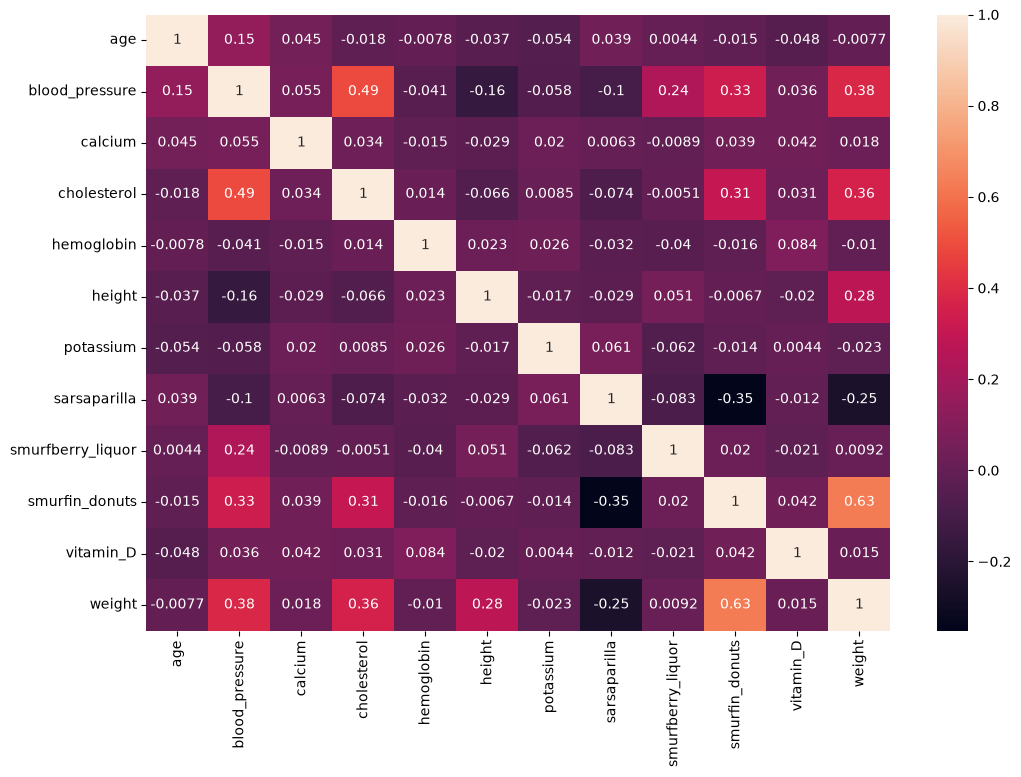

In [6]:
corr_matrix = X_train.corr()
plt.figure(figsize=(12,8))
sns.heatmap(corr_matrix, annot=True)
plt.show()

There don't seem to be any excessively correlated features, so we can't drop any with this method.

### Forward search

In [7]:

# Forward search algorithm (n_features is the number of features to select)

def forward_search(features_list, model, n_features, eval_criterion, X_train, X_val, y_train, y_val):
    selected_features = []
    remaining_features = features_list.copy()
    feature_amount_error = {}

    for i in range(1, len(features_list) + 1):
        feature_rmse_map = {}

        for feature in remaining_features:
            features = selected_features + [feature]

            model.fit(X_train[features].values, y_train.values.ravel())
            y_pred = model.predict(X_val[features].values)
            error = eval_criterion(y_val.values.ravel(), y_pred)
            feature_rmse_map[feature] = error

        best_feature = min(feature_rmse_map, key=feature_rmse_map.get)
        best_error = feature_rmse_map[best_feature]

        selected_features.append(best_feature)
        remaining_features.remove(best_feature)

        feature_amount_error[i] = best_error

    return {
        "selected_features": selected_features[:n_features],
        "feature_amount_error": feature_amount_error
    }

### Backward search

In [8]:

def backward_search(features_list, model, n_features, eval_criterion, X_train, X_val, y_train, y_val):
    remaining_features = features_list.copy()
    feature_amount_error = {}
    selected_features = remaining_features.copy() if n_features == len(remaining_features) else None

    while len(remaining_features) > 1:
        model.fit(X_train[remaining_features].values, y_train.values.ravel())
        y_pred = model.predict(X_val[remaining_features].values)
        feature_amount_error[len(remaining_features)] = eval_criterion(
            y_val.values.ravel(), y_pred
        )

        feature_rmse_map = {}

        for feature in remaining_features:
            candidate_features = remaining_features.copy()
            candidate_features.remove(feature)

            model.fit(X_train[candidate_features].values, y_train.values.ravel())
            y_pred = model.predict(X_val[candidate_features].values)

            feature_rmse_map[feature] = eval_criterion(
                y_val.values.ravel(), y_pred
            )

        feature_to_remove = min(feature_rmse_map, key=feature_rmse_map.get)
        remaining_features.remove(feature_to_remove)

        if len(remaining_features) == n_features:
            selected_features = remaining_features.copy()

    model.fit(X_train[remaining_features].values, y_train.values.ravel())
    y_pred = model.predict(X_val[remaining_features].values)
    feature_amount_error[1] = eval_criterion(y_val.values.ravel(), y_pred)

    return {
        "selected_features": selected_features,
        "feature_amount_error": feature_amount_error
    }

### Find best n features
Given that the number of features is small (max_n=12), and the size of the dataset is also small (1000 samples), we could evaluate the model with all possbile combinations of n features to find the best one.

In [ ]:
from itertools import combinations
import numpy as np
import pandas as pd


def find_best_n_features_exhaustive(model, n_features, eval_criterion,
                         X_train, X_val, y_train, y_val, standardize=False):

    best_features = None
    best_score = float("inf")
    results = []

    for features in combinations(X_train.columns, n_features):
        X_train_subset = X_train[list(features)]
        X_val_subset = X_val[list(features)]

        if standardize:
            pipelined_model = make_pipeline(
            StandardScaler(),
            model
            )
        else:
            pipelined_model = model
        pipelined_model.fit(X_train_subset, np.asarray(y_train).ravel())
        y_pred = pipelined_model.predict(X_val_subset)

        score = eval_criterion(np.asarray(y_val).ravel(), y_pred)

        results.append({
            "features": list(features),
            "score": score
        })

        if score < best_score:
            best_score = score
            best_features = list(features)

    results_df = pd.DataFrame(results).sort_values(
        by="score",
        ascending=True
    ).reset_index(drop=True)

    #print(f"Best features: {best_features}")
    #print(f"Best score: {best_score:.3f}")
    #print(f"Combinations evaluated: {len(results)}")

    return best_features, best_score, results_df

### K-Fold cross validation analysis
To unlimit ourselves from fixed train/validation set biases, we can use K-Fold analysis. We evaluate every combination of n features (from n=1 to n=12) across all folds (in this case we use 5) and later plot the error mean & stddev to find the optimal number of features to use. After that, we can determine the best combination of features for the {best_n} found, by trying each combination of {best_n} features until we find the combination with the lowest RW-RMSE. To do this, we add the number of times a feature appears in the top {best_n} in each fold, and then pick the {best_n} features that have the most appeareances across all folds.

Completed fold 1/5
Completed fold 2/5
Completed fold 3/5
Completed fold 4/5
Completed fold 5/5


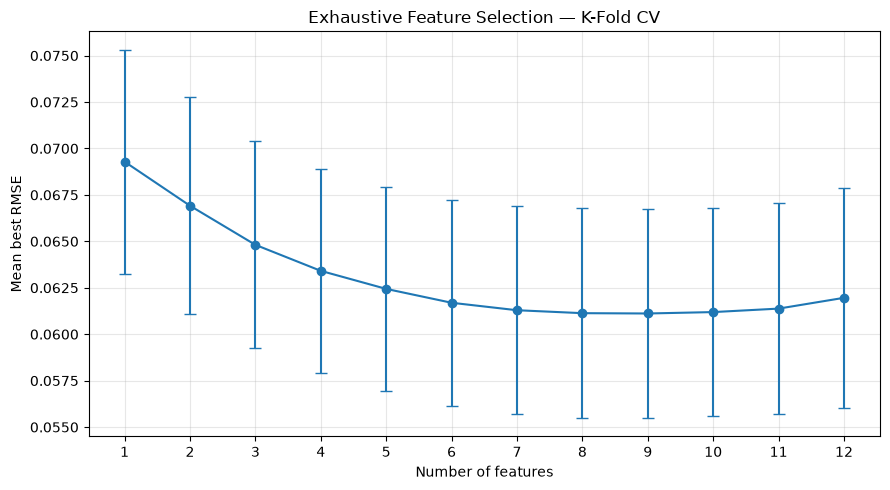

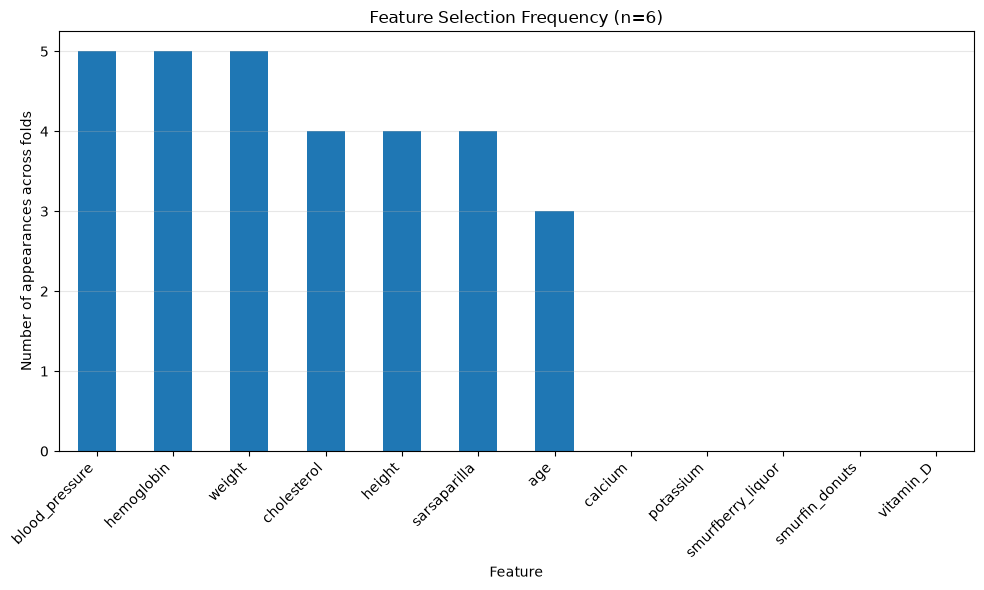


Top 6 features by selection frequency:
blood_pressure    5
hemoglobin        5
weight            5
cholesterol       4
height            4
sarsaparilla      4

Best number of features: 9 (mean RMSE = 0.0611)


In [14]:

from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def run_kfold(kf, model, n_features, X, y):
    p = X.shape[1]
    feature_names = X.columns.tolist()

    # Best RMSE for each number of features, across folds
    errors = {k: [] for k in range(1, p + 1)}

    # Feature counts for the specified n_features
    feature_counts = pd.Series(0, index=feature_names, dtype=int)

    for fold, (train_idx, val_idx) in enumerate(kf.split(X), start=1):
        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = (
            y.iloc[train_idx] if hasattr(y, "iloc") else y[train_idx]
        )
        y_val = (
            y.iloc[val_idx] if hasattr(y, "iloc") else y[val_idx]
        )

        y_train = np.asarray(y_train).ravel()
        y_val = np.asarray(y_val).ravel()

        # Evaluate every possible number of features
        for n in range(1, p + 1):
            best_score = float("inf")
            best_features = None

            # Exhaustive search over all combinations of n features
            for features in combinations(feature_names, n):
                model.fit(X_train[list(features)], y_train)
                y_pred = model.predict(X_val[list(features)])

                score = rw_rmse(y_val, y_pred)

                if score < best_score:
                    best_score = score
                    best_features = list(features)

            errors[n].append(best_score)

            # Count features only for the requested n_features
            if n == n_features:
                for feature in best_features:
                    feature_counts[feature] += 1

        print(f"Completed fold {fold}/{kf.get_n_splits()}")

    # Calculate mean and standard deviation for each n
    mean_errors = {
        n: np.mean(scores)
        for n, scores in errors.items()
    }

    std_errors = {
        n: np.std(scores, ddof=1) if len(scores) > 1 else 0
        for n, scores in errors.items()
    }

    # Plot mean best RMSE +/- standard deviation
    ks = list(range(1, p + 1))
    means = [mean_errors[k] for k in ks]
    stds = [std_errors[k] for k in ks]

    plt.figure(figsize=(9, 5))
    plt.errorbar(ks, means, yerr=stds, marker="o", capsize=4)
    plt.xlabel("Number of features")
    plt.ylabel("Mean best RMSE")
    plt.title("Exhaustive Feature Selection — K-Fold CV")
    plt.xticks(ks)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Plot feature selection frequencies for the requested n
    feature_ranking = feature_counts.sort_values(
        ascending=False, kind="stable"
    )

    plt.figure(figsize=(10, 6))
    feature_ranking.plot(kind="bar")
    plt.xlabel("Feature")
    plt.ylabel("Number of appearances across folds")
    plt.title(f"Feature Selection Frequency (n={n_features})")
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"\nTop {n_features} features by selection frequency:")
    print(feature_ranking.head(n_features).to_string())

    best_n = min(mean_errors, key=mean_errors.get)
    print(
        f"\nBest number of features: {best_n} "
        f"(mean RMSE = {mean_errors[best_n]:.4f})"
    )

    return {
        "errors": errors,
        "mean_errors": mean_errors,
        "std_errors": std_errors,
        "feature_ranking": feature_ranking,
        "selected_features": feature_ranking.head(n_features).index.tolist(),
        "best_n": best_n,
    }

kf = KFold(n_splits=5, shuffle=True, random_state=42)

results = run_kfold(kf, LinearRegression(), n_features=6, X=X_train, y=y_train)


Seeing that the performance of the model increases with the number of features (up to 9 features), then we can safely say that the best option is to use 6 features, given the restriction in the guidelines.
Our top 6 features are: **blood_pressure**, **hemoglobin**, **weight**, **cholesterol**, **height** and **sarsaparilla**.
The next step is to test our model wit these features: we train the model with the whole training dataset and later evaluate its performance on the test dataset.

In [17]:
model = LinearRegression()

features = ["blood_pressure", "hemoglobin", "weight", "cholesterol", "height", "sarsaparilla"]

model.fit(X_train[features], y_train.values.ravel())
y_pred = model.predict(X_test[features])

score = rw_rmse(y_test.values.ravel(), y_pred)

print("The model's RW-RMSE is: ", score)model = LinearRegression()

features = ["blood_pressure", "hemoglobin", "weight", "cholesterol", "height", "sarsaparilla"]

model.fit(X_train[features], y_train.values.ravel())
y_pred = model.predict(X_test[features])

score = rw_rmse(y_test.values.ravel(), y_pred)

print("The model's RW-RMSE is: ", score)


The model's RW-RMSE is:  0.07022020022518054


The error is of approximately 0.0702, whereas the mean error in the K-Fold analysis for n=6 using the X_train dataset was of around 0.0620, so we can confidently say that model predicts the test results pretty accurately.
The final step is to train our model with all the available data (X_train + X_test) to have a better model for our final prediction with the unlabeled data.

In [25]:
X = pd.concat([X_train, X_test], ignore_index=True)
y = pd.concat([y_train, y_test], ignore_index=True)

features = ["blood_pressure", "hemoglobin", "weight", "cholesterol", "height", "sarsaparilla"]

model = LinearRegression()
model.fit(X[features], y.values.ravel())
y_pred = model.predict(X_unlabeled[features])

pd.Series(y_pred).to_csv("pred/part1/y_pred.csv", index=False, header=False)

OSError: Cannot save file into a non-existent directory: 'pred/part1'